link for the dataset : "https://www.kaggle.com/datasets/mojtaba142/hotel-booking"

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("hotel_booking.csv")
df.head(3)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734


In [4]:
print(df.columns.tolist())

['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'name', 'email', 'phone-number', 'credit_card']


In [15]:
print(df.isnull().sum()[df.isnull().sum() > 0])

children         4
country        488
agent        16340
company     112593
dtype: int64


In [9]:
print(df.describe())

         is_canceled      lead_time  arrival_date_year  \
count  119390.000000  119390.000000      119390.000000   
mean        0.370416     104.011416        2016.156554   
std         0.482918     106.863097           0.707476   
min         0.000000       0.000000        2015.000000   
25%         0.000000      18.000000        2016.000000   
50%         0.000000      69.000000        2016.000000   
75%         1.000000     160.000000        2017.000000   
max         1.000000     737.000000        2017.000000   

       arrival_date_week_number  arrival_date_day_of_month  \
count             119390.000000              119390.000000   
mean                  27.165173                  15.798241   
std                   13.605138                   8.780829   
min                    1.000000                   1.000000   
25%                   16.000000                   8.000000   
50%                   28.000000                  16.000000   
75%                   38.000000            

In [17]:
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

In [19]:
df = df.dropna(subset=["is_canceled"])
df = df[df["is_canceled"].isin([0, 1])].copy()


In [20]:
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)


In [21]:
features = [
    "lead_time",
    "adr",
    "previous_cancellations",
    "total_nights"
]

In [22]:
X = df[features].replace([np.inf, -np.inf], np.nan)
y = df["is_canceled"].astype(int)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [24]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=1000))
    ]),

    "MLP": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            alpha=0.01,
            max_iter=100,
            early_stopping=True,
            random_state=42
        ))
    ])
}

In [25]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
print("\nMODEL COMPARISON")
print(results_df.round(4))

results_df.to_csv("model_comparison.csv")



MODEL COMPARISON
                     Accuracy  Precision  Recall      F1
Model                                                   
Logistic Regression    0.6882     0.6618  0.3235  0.4345
MLP                    0.7091     0.6937  0.3846  0.4949


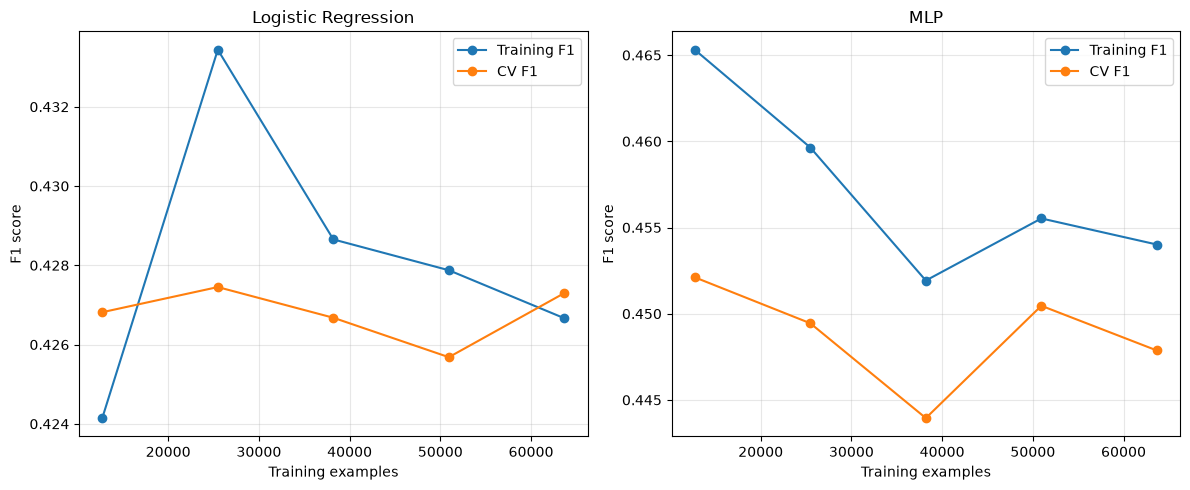

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=3,
        scoring="f1",
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=-1
    )

    ax.plot(sizes, train_scores.mean(axis=1),
            marker="o", label="Training F1")
    ax.plot(sizes, val_scores.mean(axis=1),
            marker="o", label="CV F1")

    ax.set_title(name)
    ax.set_xlabel("Training examples")
    ax.set_ylabel("F1 score")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300)
plt.show()
plt.close()


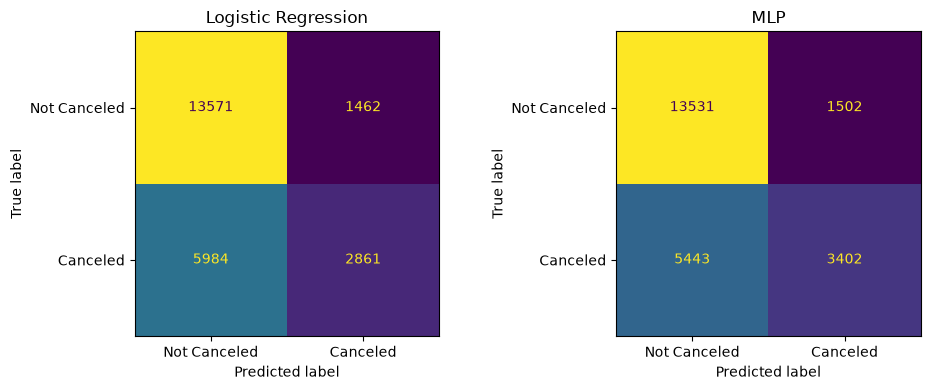

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred, labels=[0, 1]),
        display_labels=["Not Canceled", "Canceled"]
    ).plot(ax=ax, colorbar=False, values_format="d")

    ax.set_title(name)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=100)
plt.show()
plt.close()


In [32]:
for name, pred in predictions.items():
    print(f"\n{name} - Confusion Matrix")
    print(confusion_matrix(y_test, pred, labels=[0, 1]))

best_model = results_df["F1"].idxmax()
print(f"\nHigher test F1: {best_model}")
print("Recommendation: Evaluate cancellation recall and false")
print("alarms alongside F1 before deploying either model.")


Logistic Regression - Confusion Matrix
[[13571  1462]
 [ 5984  2861]]

MLP - Confusion Matrix
[[13531  1502]
 [ 5443  3402]]

Higher test F1: MLP
Recommendation: Evaluate cancellation recall and false
alarms alongside F1 before deploying either model.
